# Exercise 51 – Fitting a noisy pair potential with neural networks

**Week 10 · Training neural networks**

Forty noisy samples of the Lennard-Jones-Gauss potential – few points on the
steep repulsive wall, more in the attractive region – are fitted with networks
of different width, depth and activation function.

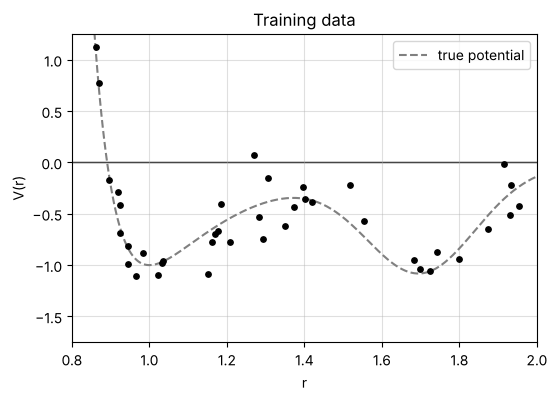

In [1]:
import matplotlib.pyplot as plt
import torch

from comphy.models import MLP
from comphy.plotting import setup_axes
from comphy.potentials import LennardJonesGauss
from comphy.training import fit

torch.manual_seed(0)

calc = LennardJonesGauss()
r_data = torch.cat([0.85 + 0.15 * torch.rand(10), 1 + torch.rand(30)])
v_data = calc.V(r_data) + 0.22 * torch.randn_like(r_data)
rs = torch.linspace(0.8, 2.0, 300)

ACTIVATIONS = {"relu": "ReLU", "leaky_relu": "Leaky ReLU", "silu": "SiLU", "softplus": "Softplus"}


def plot_data(ax, title=None):
    ax.scatter(r_data, v_data, color="black", s=15, zorder=3)
    ax.plot(rs, calc.V(rs), color="gray", ls="--", label="true potential")
    setup_axes(ax, xlim=(0.8, 2.0), ylim=(-1.75, 1.25), xlabel="r", ylabel="V(r)", title=title)


fig, ax = plt.subplots(figsize=(6, 4))
plot_data(ax, "Training data")
ax.legend()
plt.show()

## Width: two hidden layers of 8–20 neurons

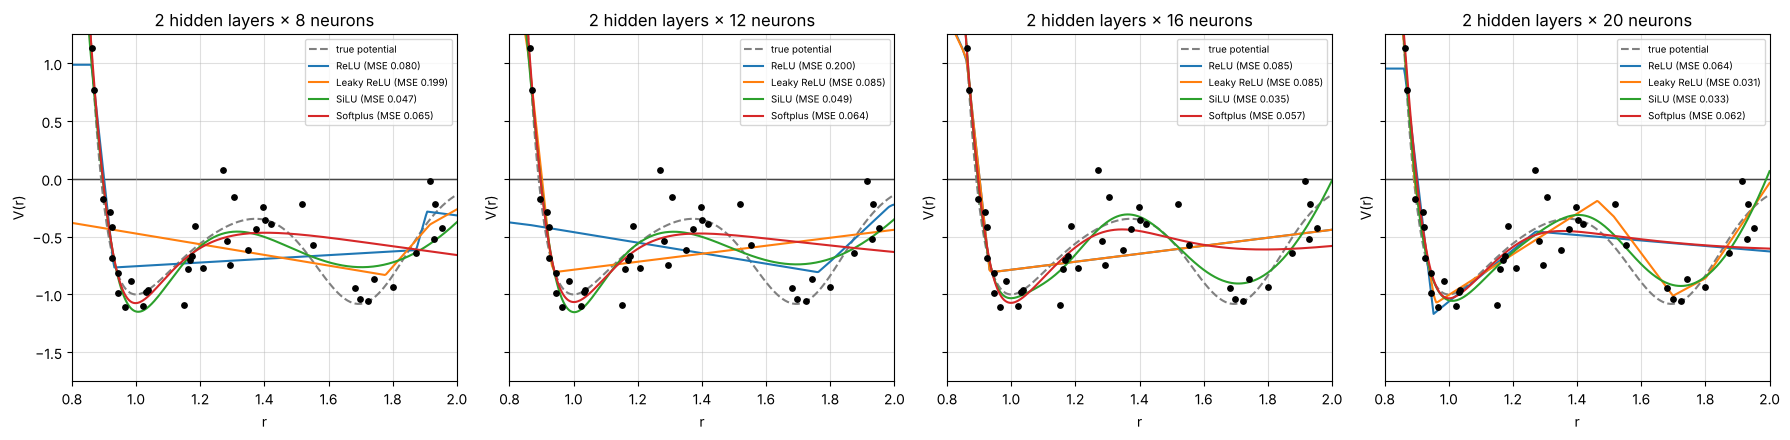

In [2]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5), sharey=True)
for ax, width in zip(axes, [8, 12, 16, 20]):
    plot_data(ax, f"2 hidden layers × {width} neurons")
    for i, (act, name) in enumerate(ACTIVATIONS.items()):
        model = MLP(hidden=(width, width), activation=act)
        loss = fit(model, r_data, v_data, steps=1000)[-1]
        with torch.no_grad():
            ax.plot(rs, model(rs), color=f"C{i}", label=f"{name} (MSE {loss:.3f})")
    ax.legend(fontsize=7, loc="upper right")
fig.tight_layout()
plt.show()

## Depth: three hidden layers, with a little weight decay

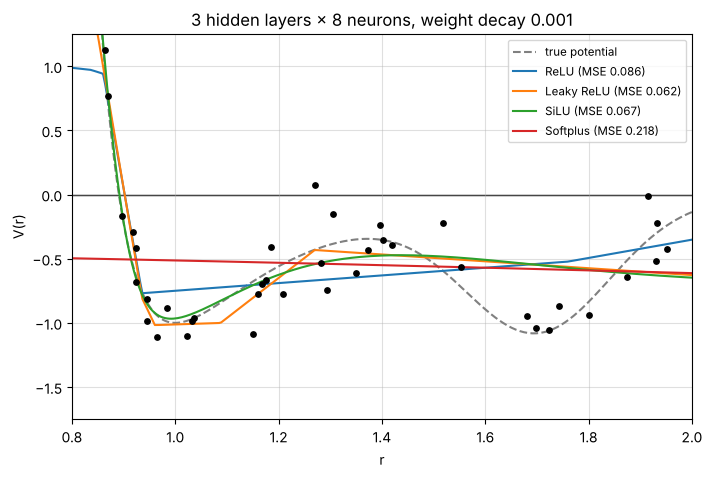

In [3]:
fig, ax = plt.subplots(figsize=(8, 5))
plot_data(ax, "3 hidden layers × 8 neurons, weight decay 0.001")
for i, (act, name) in enumerate(ACTIVATIONS.items()):
    model = MLP(hidden=(8, 8, 8), activation=act)
    loss = fit(model, r_data, v_data, steps=1000, weight_decay=0.001)[-1]
    with torch.no_grad():
        ax.plot(rs, model(rs), color=f"C{i}", label=f"{name} (MSE {loss:.3f})")
ax.legend(fontsize="small")
plt.show()

## Training longer
A 3 × 12 SiLU network trained for 10 000 steps starts to chase the noise.

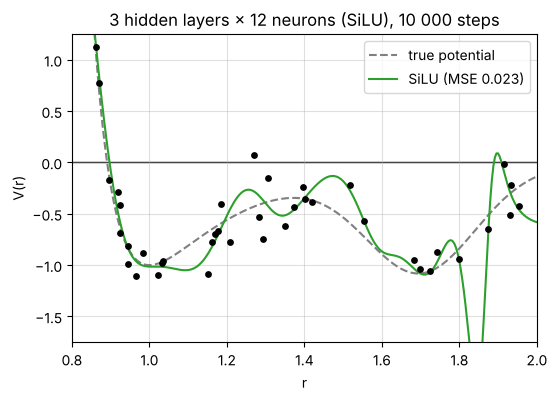

In [4]:
model = MLP(hidden=(12, 12, 12), activation="silu")
loss = fit(model, r_data, v_data, steps=10_000)[-1]

fig, ax = plt.subplots(figsize=(6, 4))
plot_data(ax, "3 hidden layers × 12 neurons (SiLU), 10 000 steps")
with torch.no_grad():
    ax.plot(rs, model(rs), color="C2", label=f"SiLU (MSE {loss:.3f})")
ax.legend()
plt.show()